## Homework 10

In this homework, you are going to use and compare two different trackers (of your liking) and compare the results.

### Step 1
Decide what video you are going to use for this homework, select an object and generate the template. You can use any video you want (your own, from Youtube, etc.)
and track any object you want (e.g. a car, a pedestrian, etc.).

In [1]:
import os
import cv2
from matplotlib import pyplot as plt

In [ ]:
# Відео: Formula 1 Turkish GP 2021 
video_path = '/Users/andriizemlianyi/Code/zemand-learning/Computer Vision/r_d/r_d-computer-vision-v2-master/lesson_10/data/formula1_turkish_gp_2021.webm'

start_sec = 16      # з якої секунди беремо кадри
n_frames = 15       # скільки кадрів буде в нашій послідовності
step = 3            # відео має 60 fps, тому беремо кожен 3-й кадр, щоб машина встигала зсунутись

# Відкриваємо відео
cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)

# Перескакуємо на потрібну секунду
cap.set(cv2.CAP_PROP_POS_FRAMES, int(start_sec * fps))

# Читаємо кадри і складаємо в список frames
frames = []
count = 0
while len(frames) < n_frames:
    ok, frame = cap.read()
    if not ok:
        break
    if count % step == 0:
        frames.append(frame)
    count = count + 1
cap.release()

print('Кадрів у списку:', len(frames))

Кадрів у списку: 15


Text(0.5, 1.0, 'Шаблон')

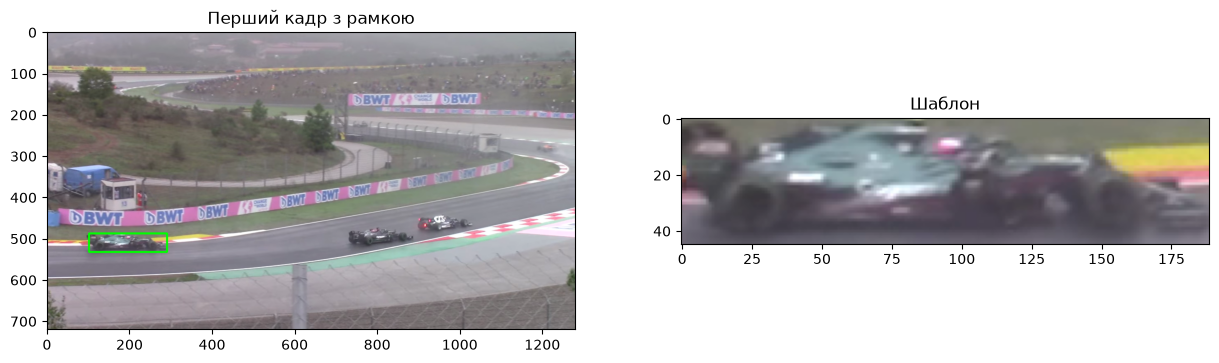

In [3]:
# Обираємо об'єкт: зелений болід (Aston Martin) зліва внизу на першому кадрі
# Рамка у форматі (x, y, w, h): лівий верхній кут, ширина, висота
box = (102, 487, 189, 45)

x, y, w, h = box
first_frame = frames[0]

# Шаблон - це шматок першого кадру, який ми будемо відстежувати
template = first_frame[y:y + h, x:x + w]

# Малюємо рамку на копії першого кадру
frame_with_box = first_frame.copy()
cv2.rectangle(frame_with_box, (x, y), (x + w, y + h), (0, 255, 0), 3)

plt.figure(figsize=(15, 6))
plt.subplot(121)
plt.imshow(cv2.cvtColor(frame_with_box, cv2.COLOR_BGR2RGB))
plt.title('Перший кадр з рамкою')
plt.subplot(122)
plt.imshow(cv2.cvtColor(template, cv2.COLOR_BGR2RGB))
plt.title('Шаблон')

### Step 2
Initialize a tracker (e.g. KCF).

In [4]:
# Створюємо трекер KCF і кажемо йому, що відстежувати: перший кадр і рамка
tracker_kcf = cv2.TrackerKCF_create()
tracker_kcf.init(frames[0], box)

### Step 3
Run the tracker on the video and the selected object. Run the tracker for around 10-15 frames.

In [5]:
# Списки для результатів. На першому кадрі рамка - та, яку ми задали самі
boxes_kcf = [box]
ok_kcf = [True]

# Проходимо по решті кадрів (з другого) і просимо трекер знайти об'єкт
for i in range(1, len(frames)):
    ok, new_box = tracker_kcf.update(frames[i])
    boxes_kcf.append(new_box)
    ok_kcf.append(ok)

print('KCF: кадрів без втрати об\'єкта:', ok_kcf.count(True), 'з', len(frames))

KCF: кадрів без втрати об'єкта: 13 з 15


### Step 4
For each frame, print the bounding box on the image and save it.

In [6]:
# Папка для збережених кадрів (поза репозиторієм, щоб вони не потрапили в git)
out_kcf = os.path.expanduser('~/hw10_tracking_frames/KCF')
os.makedirs(out_kcf, exist_ok=True)

for i in range(len(frames)):
    img = frames[i].copy()
    # Якщо трекер втратив об'єкт, рамки немає, зберігаємо кадр без неї
    if ok_kcf[i]:
        x, y, w, h = boxes_kcf[i]
        x, y, w, h = int(x), int(y), int(w), int(h)
        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 3)
    cv2.imwrite(out_kcf + '/frame_' + str(i) + '.jpg', img)

print('Кадри збережено в', out_kcf)

Кадри збережено в /Users/andriizemlianyi/hw10_tracking_frames/KCF


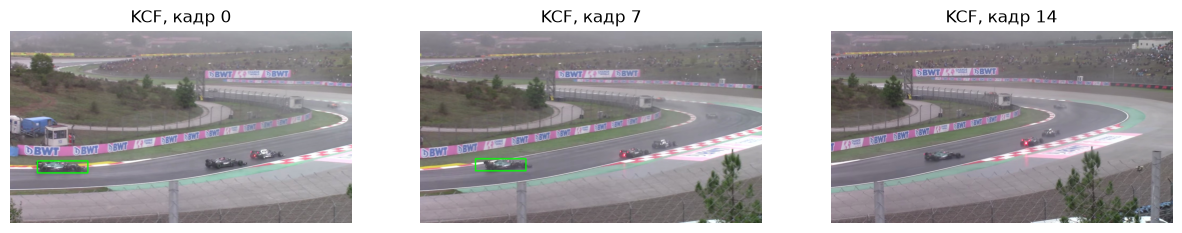

In [7]:
# Дивимось на кілька кадрів: початок, середина, кінець
plt.figure(figsize=(15, 4))
shown = [0, 7, 14]
for k in range(len(shown)):
    i = shown[k]
    img = cv2.imread(out_kcf + '/frame_' + str(i) + '.jpg')
    plt.subplot(1, 3, k + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title('KCF, кадр ' + str(i))
    plt.axis('off')

### Step 5
Select a different tracker (e.g. CSRT) and repeat steps 2, 3 and 4.

In [8]:
# Крок 2 для CSRT
tracker_csrt = cv2.TrackerCSRT_create()
tracker_csrt.init(frames[0], box)

In [9]:
# Крок 3 для CSRT
boxes_csrt = [box]
ok_csrt = [True]

for i in range(1, len(frames)):
    ok, new_box = tracker_csrt.update(frames[i])
    boxes_csrt.append(new_box)
    ok_csrt.append(ok)

print('CSRT: кадрів без втрати об\'єкта:', ok_csrt.count(True), 'з', len(frames))

CSRT: кадрів без втрати об'єкта: 15 з 15


In [10]:
# Крок 4 для CSRT
out_csrt = os.path.expanduser('~/hw10_tracking_frames/CSRT')
os.makedirs(out_csrt, exist_ok=True)

for i in range(len(frames)):
    img = frames[i].copy()
    if ok_csrt[i]:
        x, y, w, h = boxes_csrt[i]
        x, y, w, h = int(x), int(y), int(w), int(h)
        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 3)
    cv2.imwrite(out_csrt + '/frame_' + str(i) + '.jpg', img)

print('Кадри збережено в', out_csrt)

Кадри збережено в /Users/andriizemlianyi/hw10_tracking_frames/CSRT


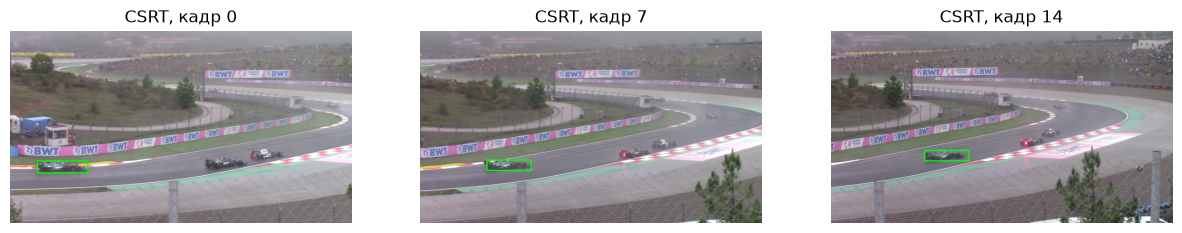

In [11]:
plt.figure(figsize=(15, 4))
shown = [0, 7, 14]
for k in range(len(shown)):
    i = shown[k]
    img = cv2.imread(out_csrt + '/frame_' + str(i) + '.jpg')
    plt.subplot(1, 3, k + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title('CSRT, кадр ' + str(i))
    plt.axis('off')

### Step 6
Compare the results:
* Do you see any differences? If so, what are they?
Так. Обидва трекери в цілому йдуть за болідом, але KCF на останніх кадрах втратив болід і повернув трохи рамку. CSRT не втратив його жодного разу.

* Does one tracker perform better than the other? In what way?
На цьому відео очевидно CSRT кращий: він не втратив об'єкт, пристосувався до зміни розміру й рамка ближче до машини. KCF гірший, бо його шаблон із фіксованим розміром не підходить, коли об'єкт зменшується, і в кінці він взагалі загубив його.
